# Petal-piston reconstruction from photonic-lantern signals: workbench

The working notebook for PLREC. It combines `trainMLP.ipynb`,
`trainMLP_multiwavelength.ipynb` and `PL_EML.ipynb` into one sequence, as
the starting point for refining them.

**Task.** Estimate the 5 petal pistons of the ANDES DM modal basis (modes
0-4; the sixth petal is the reference) from the light in the output cores of
a photonic lantern simulated with cbeam.

| | Part A: one wavelength | Part B: 41 wavelengths |
|---|---|---|
| pistons | uniform in +-span (300 nm at 800 nm, 500 nm at 1200 nm), inside +-lambda/2 | uniform in +-5 um, many wavelengths |
| signals | n_cores camera signals at the design wavelength, unit coupled power | n_cores channel powers x 41 wavelengths across the band, fraction of incident power |
| samples | 10000 (8000 train) | 50000 (40000 train) |
| dataset | `<data>/single*.npz` | `<data>/spectral_41wl.npz` |

At one wavelength a piston is seen only modulo lambda, so Part A stays inside
the unambiguous range. Part B goes far beyond it, and only the combination of
wavelengths can resolve the piston: either one model on the whole spectrum,
or one model per wavelength on the wrapped piston, fused by a
multi-wavelength unwrap.

Each part goes from the simplest reconstructor to the most complex and ends
with a comparison; the summary at the end puts both side by side. The MLP
hyperparameter search of `scripts/mlp_hpo.py` (pl19_800 only) is in
`mlp_hpo.ipynb`. The helper functions are in `ml_reconstruct/notebook.py`.

**Lantern.** The notebook runs for the lantern preset named by the environment
variable `CBEAM_LANTERN` (cbeam's `batch_pipeline.LANTERNS`): `pl19_800`, the
reference 19-port lantern at 800 nm (default); `pl7_1200`, 7 ports at
1200 nm; `pl19_1200`, 19 ports at 1200 nm in the same fibres as `pl7_1200`.
Its settings (piston range, polynomial budgets, data folder) are in
`ml_reconstruct.presets`; executed copies for each lantern are in
`runs/<lantern>/`.

Fitted models are cached under the lantern's `cache_*` folders by name (the
same names as the three single notebooks, so a run loads them instead of
refitting); set `RETRAIN = True` to refit everything. The cache does not check
the data: delete those folders after regenerating a dataset.


In [1]:
import os
os.environ["CBEAM_BACKEND"] = "numpy"

import numpy as np
import matplotlib.pyplot as plt
import ml_reconstruct as ml
from ml_reconstruct.notebook import *            # helpers: datasets, scoring, plots, fit-or-load

RETRAIN = False                 # True: refit every model instead of loading the cache
M_MODES = 5                     # DM modes 0..4 (petal pistons)

from ml_reconstruct.presets import settings
S = settings()                  # this lantern's settings (CBEAM_LANTERN)
LANTERN, DATA = S["lantern"], S["data_dir"]
print(f"lantern {LANTERN}, data in {DATA}")

lantern pl7_1200, data in data/ml/pl7_1200


# Part A: one wavelength

Origin: `trainMLP.ipynb`.

## A1. Dataset

Each sample is a random configuration of the 5 pistons, propagated through
the lantern. Each core's signal is the mean of a 5x5-pixel window of the
imaged output face around the core centre, with the input normalised to unit
coupled power (`ml_reconstruct.simulate.simulate_core_images`). If the file
is missing it is simulated: 15-40 minutes on the numpy backend.

**Why the port count matters at one wavelength.** Each single piston is kept
inside +-lambda/2, but two petals can differ by twice that. The signals of an
N-port lantern, normalised, have N - 1 independent values; a smooth map of the
5 pistons is in general one-to-one over a large range only into 11 or more
dimensions, otherwise it folds onto itself and different piston sets give the
same signals. 19 ports (18 values) resolve the range; 7 ports (6 values) do
not: on `pl7_1200` at +-500 nm every reconstructor stops near 220 nm against
288 nm for no skill, while the same lantern reconstructs smaller pistons well.
`pl19_1200` (same fibres and wavelength, 19 ports) is the direct test.

Signals and pistons are standardised with the training-split statistics.


In [2]:
A_SAMPLES, A_TRAIN = 10000, 8000
A_SPAN_NM = S["single_span_nm"]
A_DATASET = S["single"]
cacheA = ml.ModelCache(f"{DATA}/cache_single", retrain=RETRAIN)
# simulated (with rng=0) only if the file is missing
dsA = load_or_simulate(A_DATASET, "make_single_dataset", n=A_SAMPLES, n_train=A_TRAIN, span_nm=A_SPAN_NM,
                       lantern=LANTERN)

In [3]:
SA_tr, CA_tr = dsA.train
SA_va, CA_va = dsA.val
xsA, ysA = ml.Standardizer().fit(SA_tr), ml.Standardizer().fit(CA_tr)
XA_tr, XA_va = xsA.transform(SA_tr), xsA.transform(SA_va)
YA_tr, YA_va = ysA.transform(CA_tr), ysA.transform(CA_va)
print(f"{len(SA_tr)} training / {len(SA_va)} validation samples, {SA_tr.shape[1]} cores, "
      f"{CA_tr.shape[1]} pistons, std {CA_tr.std():.0f} nm")

RESULTS_A, DOF_A = {}, {}   # model -> per-piston validation RMSE [nm], degrees of freedom per piston

8000 training / 2000 validation samples, 7 cores, 5 pistons, std 288 nm


## A1b. A look at the dataset

The piston distribution, and the core signals across the training set: their
spread per core, their mean and relative variation on the output layout, and
how they correlate with each piston. Correlation with p shows the part of a
core's response that is odd in the piston, and correlation with p^2 the even
part.

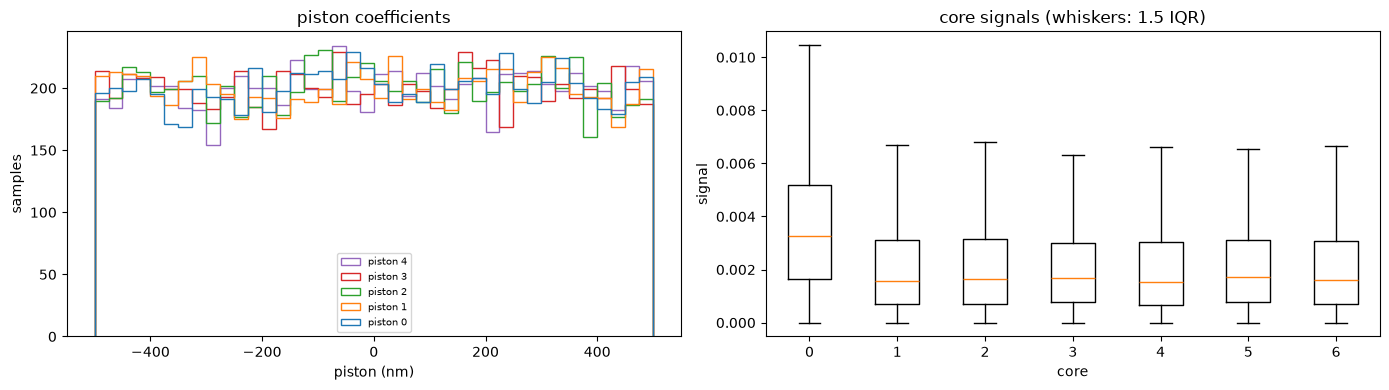

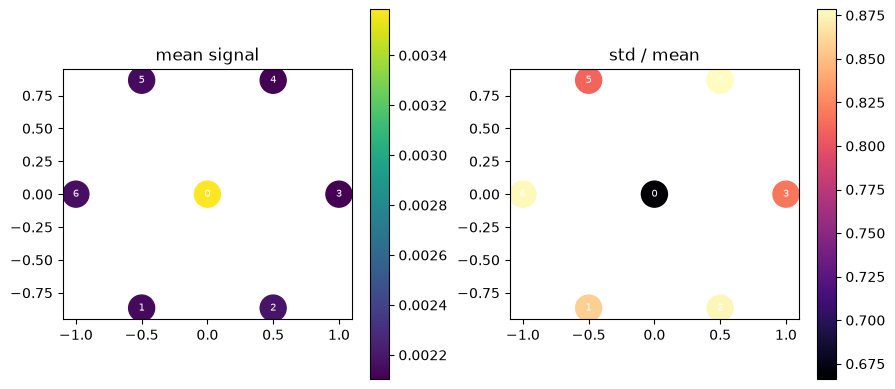

In [4]:
plot_single_overview(SA_tr, CA_tr, dsA.core_xy)

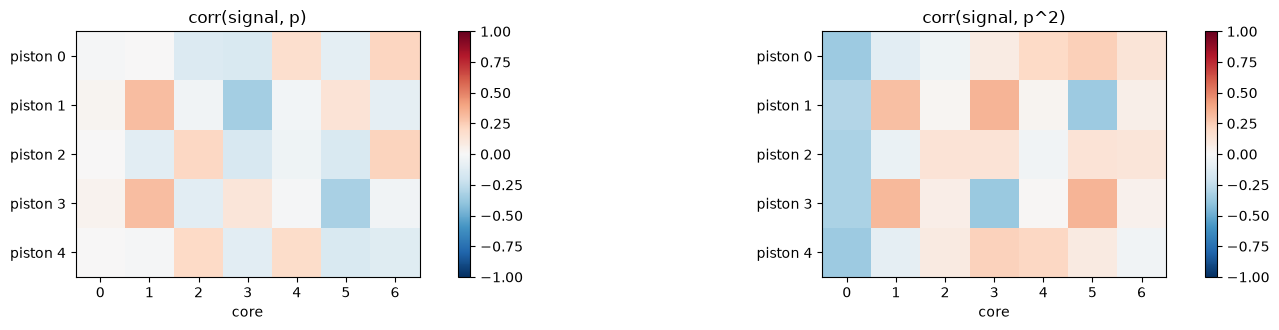

sum of the 7 signals per sample: mean 0.01643, std / mean 0.35%


In [5]:
plot_signal_piston_correlation(SA_tr, CA_tr)
tot = SA_tr.sum(axis=1)
print(f"sum of the {SA_tr.shape[1]} signals per sample: mean {tot.mean():.4g}, std / mean {tot.std() / tot.mean():.2%}")

## A2. Baseline: k-nearest neighbours

k-NN needs no training and shows how well the signals determine the pistons
at all.

In [6]:
from sklearn.neighbors import KNeighborsRegressor

knnA = cacheA("kNN", lambda: KNeighborsRegressor(5, weights="distance").fit(XA_tr, YA_tr))
score(RESULTS_A, "kNN", knnA.predict(XA_va), CA_va, ys=ysA)
DOF_A["kNN"] = n_dof(knnA)          # k-NN fits nothing: the training values it keeps, per piston

[cache] loaded kNN
kNN                    mean   239.33 nm   per piston [235.27 247.38 225.51 252.29 236.18]


## A3. MLP

Three hidden layers of 128 units, Adam, 500 epochs; the weights of the epoch
with the lowest validation loss are kept.

MLP [7, 128, 128, 128, 5]: best epoch 410 of 500


MLP                    mean   226.44 nm   per piston [229.92 230.88 206.04 239.12 226.22]


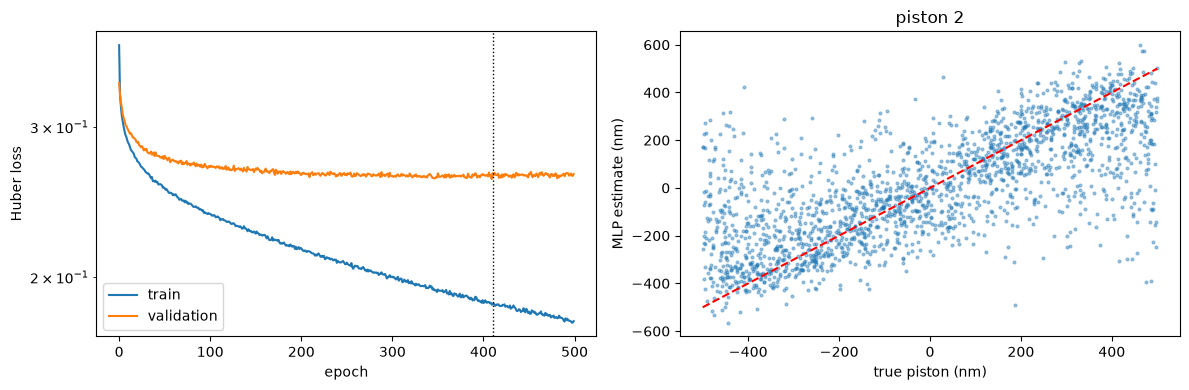

In [7]:
LAYERS_A = [XA_tr.shape[1], 128, 128, 128, M_MODES]
MLP_A = f"{DATA}/cache_single/mlp-{'x'.join(map(str, LAYERS_A))}-e500.npz"
paramsA, histA = fit_or_load_mlp(MLP_A, LAYERS_A, XA_tr, YA_tr, XA_va, YA_va, epochs=500, lr=3e-4,
                                 retrain=RETRAIN)
CA_mlp = ysA.inverse(np.asarray(ml.mlp_forward(paramsA, XA_va)))
score(RESULTS_A, "MLP", CA_mlp, CA_va)
DOF_A["MLP"] = n_dof(paramsA)
plot_mlp(histA, CA_va, CA_mlp, k=2, span=A_SPAN_NM)

## A4. Polynomial models


### Zernike representation of the core signals

The core signals, placed at their cores on the unit disk, projected onto the
first `n_zern` Noll Zernikes (36 for 19 cores; 10 for 7 cores, the fewest with
full rank on one hexagonal ring, where coma coincides with tilt). The sampled
basis has rank n_cores, so this is a change of variables rather than a
compression, shown as a diagnostic of how the mean core signal decomposes.


Zernike basis (7, 10), rank 7


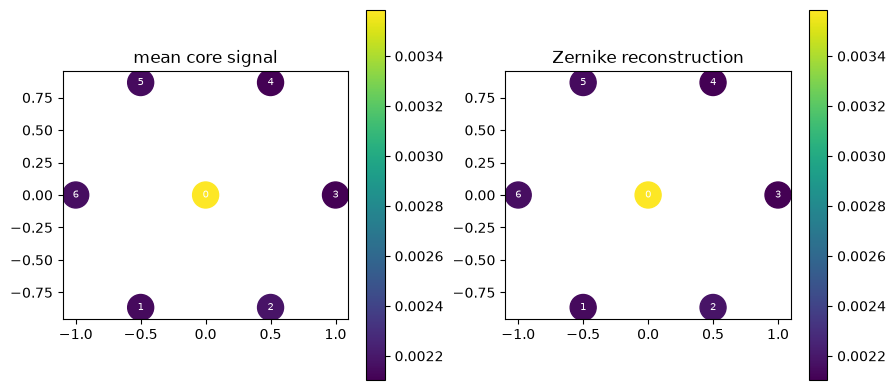

In [8]:
N_ZERN = S["n_zern"]
ZBASIS = ml.zernike_basis(dsA.core_xy, N_ZERN, fill=0.8)[0]
ZPROJ = ml.modal_projector(ZBASIS)
print(f"Zernike basis {ZBASIS.shape}, rank {np.linalg.matrix_rank(ZBASIS)}")

# diagnostic only
s_mean = SA_tr.mean(axis=0)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
hexmap(ax[0], dsA.core_xy, s_mean, "mean core signal")
hexmap(ax[1], dsA.core_xy, ZBASIS @ (ZPROJ @ s_mean), "Zernike reconstruction")
plt.tight_layout(); plt.show()


### Dense degree-2 polynomial ridge on the core signals

In [9]:
# Dense ridge on every degree-2 monomial of the core signals: the complete
# quadratic model.
model = cacheA("fiber-d2", lambda: ml.fit_dense_poly_ridge(XA_tr, YA_tr, 2))
DOF_A["fiber-d2"] = n_dof(model)
score(RESULTS_A, "fiber-d2", ml.predict_dense_poly_ridge(model, XA_va), CA_va, ys=ysA,
      note=f"   ({model[0].n_output_features_} terms)")


[cache] fitted and saved fiber-d2
fiber-d2               mean   243.20 nm   per piston [246.47 247.68 232.76 246.76 242.35]   (35 terms)


array([246.46854517, 247.67753813, 232.75608424, 246.76212998,
       242.35342366])

### Compact model: OMP with a term budget K

Orthogonal Matching Pursuit keeps at most K of the degree-3 monomials of the
standardised core signals per piston (1539 for 19 cores, 119 for 7) (after screening them by correlation
with the piston). The sweep shows the accuracy / size trade-off.

**Choosing the OMP budget K, per lantern.**

- *19 cores* (1539 degree-3 monomials). On `pl19_800` the sweep falls smoothly
  -- 15.5 nm at K = 1100, 9.3 nm at K = 1275 -- and stops at **K = 1281**,
  where every piston keeps its own natural support (1280 or 1281 monomials);
  every larger budget, up to the full cubic basis, reproduces that fit to the
  last digit (8.41 nm). K = 1282 is that saturated model counted with its
  intercept: its degrees of freedom per piston. `pl19_1200` uses the same
  budget; its own sweep shows whether it saturates at the same point.
- *7 cores* (119 monomials). On `pl7_1200` the sweep is nearly flat (from
  ~250 nm at K = 5 to ~224 nm with the complete cubic, K = 119) and there is
  no saturation point to find; the floor is the ambiguity of 7 signals, not
  the model, so K = 119 is used.


In [10]:
SCREEN_A = 9000
KS_A = S["omp_ks"]
RECORD_KS_A = S["omp_record_wb"]

F3A_tr, F3A_va, _, poly_d3A = ml.poly_features(XA_tr, XA_va, 3)   # core-signal monomials
omp_fits_A = lambda K: omp_fits(cacheA, "fiber-omp", F3A_tr, YA_tr, K, SCREEN_A)
sweepA = omp_sweep(cacheA, "fiber-omp", F3A_tr, YA_tr, F3A_va, CA_va, ysA, KS_A, SCREEN_A)


[cache] loaded fiber-omp-K5
K=    5:     5.0 terms/piston   mean RMSE 259.5 nm
[cache] loaded fiber-omp-K10
K=   10:    10.0 terms/piston   mean RMSE 249.7 nm
[cache] loaded fiber-omp-K20
K=   20:    20.0 terms/piston   mean RMSE 243.1 nm
[cache] loaded fiber-omp-K30
K=   30:    30.0 terms/piston   mean RMSE 239.8 nm
[cache] loaded fiber-omp-K40
K=   40:    40.0 terms/piston   mean RMSE 237.7 nm
[cache] loaded fiber-omp-K60
K=   60:    60.0 terms/piston   mean RMSE 236.7 nm
[cache] loaded fiber-omp-K80
K=   80:    80.0 terms/piston   mean RMSE 236.3 nm
[cache] loaded fiber-omp-K100
K=  100:   100.0 terms/piston   mean RMSE 229.3 nm
[cache] loaded fiber-omp-K119
K=  119:   118.0 terms/piston   mean RMSE 228.5 nm


[cache] loaded fiber-omp-K40
fiber-omp-K40          mean   237.72 nm   per piston [242.18 239.85 226.43 243.93 236.22]
[cache] loaded fiber-omp-K40
[cache] loaded fiber-omp-K119
fiber-omp-K119         mean   228.50 nm   per piston [230.6  233.06 217.84 235.   225.97]
[cache] loaded fiber-omp-K119


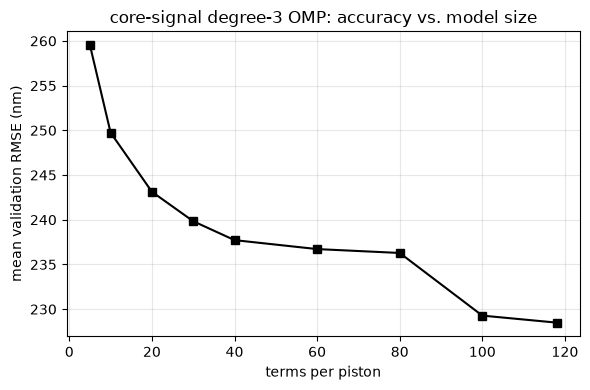

In [11]:
for K in RECORD_KS_A:
    score(RESULTS_A, f"fiber-omp-K{K}", omp_predict_all(F3A_va, omp_fits_A(K)), CA_va, ys=ysA)
    DOF_A[f"fiber-omp-K{K}"] = n_dof(omp_fits_A(K))
plot_omp_sweep(sweepA, "core-signal degree-3 OMP: accuracy vs. model size")


## A5. What the OMP models use

### Which monomials does OMP keep?

Kept vs. available monomials per degree at K = `k_table` (500 for 19 cores, 60
for 7), and how the degree mix of
the kept terms changes with the budget.

In [12]:
K_TABLE, KS_MIX = S["k_table"], S["ks_mix"]
degree = poly_d3A.powers_.sum(axis=1)
degs = np.arange(1, degree.max() + 1)
total = np.array([(degree == d).sum() for d in degs])
kept = kept_by_degree(omp_fits_A(K_TABLE), degree)
print(f"K = {K_TABLE}: kept / available monomials per degree (one column per piston)")
for i, d in enumerate(degs):
    print(f"  degree {d}: {total[i]:5d} available, kept {kept[:, i]}  ({kept[:, i].mean() / total[i]:.1%})")

[cache] loaded fiber-omp-K60
K = 60: kept / available monomials per degree (one column per piston)
  degree 1:     7 available, kept [5 5 6 6 5]  (77.1%)
  degree 2:    28 available, kept [13 16 15 15 15]  (52.9%)
  degree 3:    84 available, kept [42 39 39 39 40]  (47.4%)


[cache] loaded fiber-omp-K5
[cache] loaded fiber-omp-K10
[cache] loaded fiber-omp-K20
[cache] loaded fiber-omp-K30
[cache] loaded fiber-omp-K60


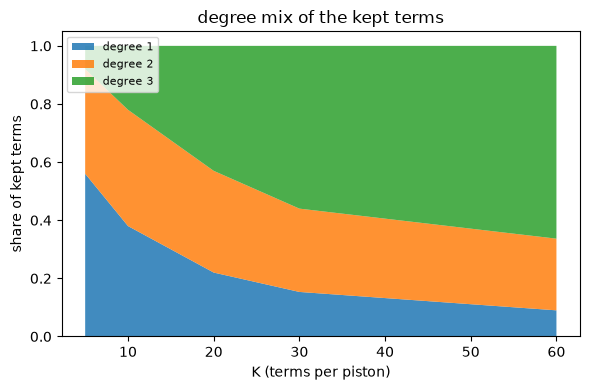

In [13]:
mix = np.array([kept_by_degree(omp_fits_A(K), degree).sum(axis=0) for K in KS_MIX], float)
plot_degree_mix(KS_MIX, (mix / mix.sum(axis=1, keepdims=True)).T)

### Which core signals matter?

For the largest recorded OMP model: the total |coefficient| (in standardised units) of
the monomials each core signal appears in, per piston (core 0 is the central
one).

[cache] loaded fiber-omp-K119


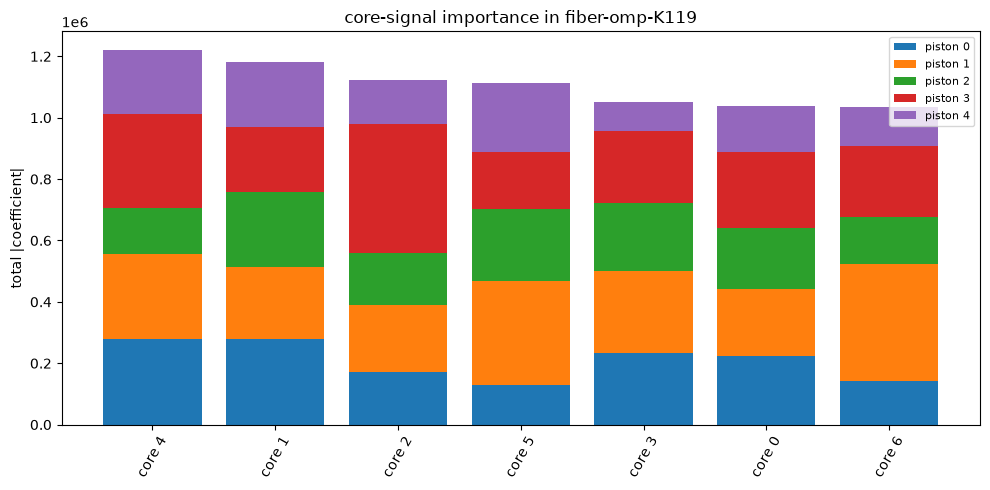

In [14]:
K = S["k_importance"]
mass = omp_variable_importance(omp_fits_A(K), poly_d3A.powers_)   # (piston, core signal)
vnames = [f"core {i}" for i in range(XA_tr.shape[1])]
plot_stacked_importance(mass, vnames, f"core-signal importance in fiber-omp-K{K}")


## A6. Part A comparison

  fiber-d2                 243.20 nm   per piston [246.47 247.68 232.76 246.76 242.35]          36 dof/piston
  kNN                      239.33 nm   per piston [235.27 247.38 225.51 252.29 236.18]      64,000 dof/piston
  fiber-omp-K40            237.72 nm   per piston [242.18 239.85 226.43 243.93 236.22]          41 dof/piston
  fiber-omp-K119           228.50 nm   per piston [230.6  233.06 217.84 235.   225.97]         119 dof/piston
  MLP                      226.44 nm   per piston [229.92 230.88 206.04 239.12 226.22]       6,939 dof/piston


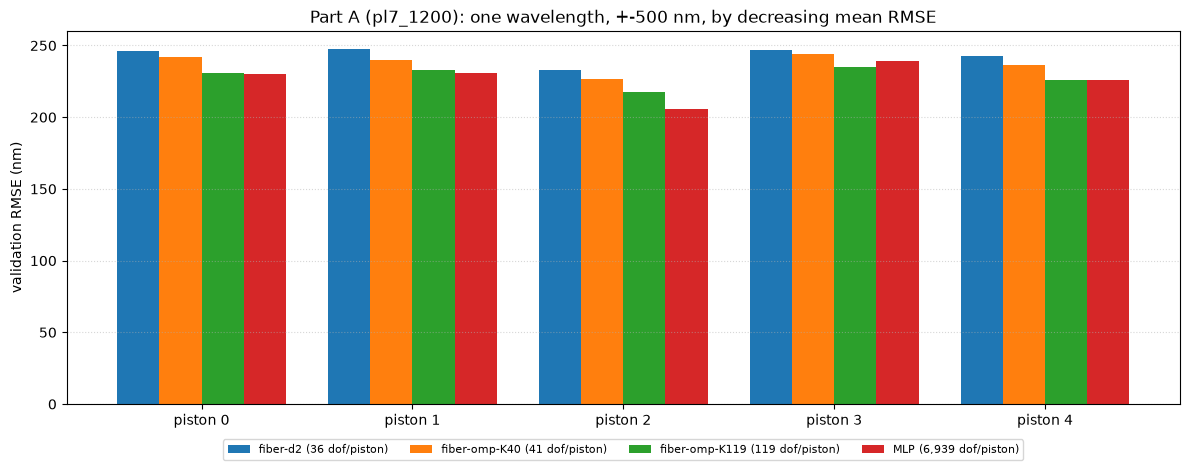

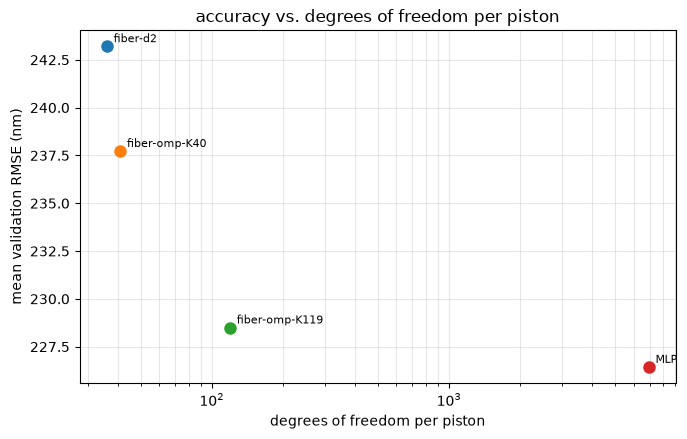

In [15]:
show_results(RESULTS_A, f"Part A ({LANTERN}): one wavelength, +-{A_SPAN_NM:.0f} nm, by decreasing mean RMSE",
             logy=False, sort=True, dof=DOF_A, exclude=("kNN",))

# Part B: 41 wavelengths, +-5 um

Origin: `trainMLP_multiwavelength.ipynb` (single models on the whole
spectrum) and `PL_EML.ipynb` (per-wavelength models and the unwrap).

## B1. Dataset

One lantern characterization per wavelength (cached in cbeam's
`examples/data/`), then all samples propagated wavelength by wavelength
(`ml_reconstruct.simulate.simulate_spectra`). Each signal is the power in
one output channel as a fraction of the incident power, so it includes the
input coupling efficiency. Simulating 50000 samples at 41 wavelengths in one
process takes many hours; `gen_datasets.py` / `run_gen.sh` split it into 410
independent pieces (41 wavelengths x 10 chunks) run in parallel, which is how
the current file was made.

The signals are standardised per (wavelength, core) column with the
training statistics. `XB_*` is the flat (41 x n_cores)-long view used by the
full-spectrum models, `X3B_*` the same numbers as (n, wavelength, core) for
the per-wavelength models.

In [16]:
B_SAMPLES, B_TRAIN = 50000, 40000
B_SPAN_NM = 5000.0
from ml_reconstruct.simulate import bp            # cbeam's batch_pipeline
WAVELENGTHS_NM = np.linspace(*bp.get_simulation_parameters(lantern=LANTERN)["band_nm"], 41)
B_DATASET = S["spectral"]
cacheB = ml.ModelCache(f"{DATA}/cache_spectral", retrain=RETRAIN)     # full-spectrum models
cacheW = ml.ModelCache(f"{DATA}/cache_perlambda", retrain=RETRAIN)    # per-wavelength and global OMP
# simulated (with rng=0) only if the file is missing: hours, see gen_datasets.py for a parallel run
dsB = load_or_simulate(B_DATASET, "make_spectral_dataset", n=B_SAMPLES, n_train=B_TRAIN,
                       span_nm=B_SPAN_NM, wavelengths_nm=WAVELENGTHS_NM, lantern=LANTERN)

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


In [17]:
SB_tr, CB_tr = dsB.train
SB_va, CB_va = dsB.val
lam = dsB.wavelengths_nm
n_wl, n_cores = SB_tr.shape[1:]
xsB, ysB = ml.Standardizer().fit(SB_tr.reshape(len(SB_tr), -1)), ml.Standardizer().fit(CB_tr)
XB_tr = xsB.transform(SB_tr.reshape(len(SB_tr), -1))
XB_va = xsB.transform(SB_va.reshape(len(SB_va), -1))
X3B_tr, X3B_va = XB_tr.reshape(SB_tr.shape), XB_va.reshape(SB_va.shape)
YB_tr, YB_va = ysB.transform(CB_tr), ysB.transform(CB_va)
print(f"{len(XB_tr)} training / {len(XB_va)} validation samples, {n_wl} wavelengths "
      f"({lam[0]:.0f}-{lam[-1]:.0f} nm) x {n_cores} cores = {XB_tr.shape[1]} inputs; "
      f"pistons std {CB_tr.std():.0f} nm")

40000 training / 10000 validation samples, 41 wavelengths (1100-1300 nm) x 7 cores = 287 inputs; pistons std 2883 nm


In [18]:
RESULTS_B, DOF_B = {}, {}   # model -> per-piston validation RMSE [nm], degrees of freedom per piston
score(RESULTS_B, "no skill (mean)", np.broadcast_to(CB_tr.mean(0), CB_va.shape), CB_va)
DOF_B["no skill (mean)"] = 1          # one constant per piston

no skill (mean)        mean  2893.08 nm   per piston [2888.28 2880.81 2891.36 2908.63 2896.31]


## B1b. A look at the dataset

The rows below cover:

- **Total channel power vs. wavelength.** The total for the random pistons
  of the training set, compared with a flat wavefront when the ramp results
  of `multi_wavelength.ipynb` are available.
- **One sample's spectra.**
- **Mean channel power and relative variation, per (wavelength, core).**
- **How much each wavelength sees each piston, linearly.** This is the R^2 of
  a linear fit of the piston's phasor (sin, cos)(2 pi p / lambda) on the
  channel powers at that wavelength, averaged over sin and cos, on a quarter
  of the training rows. It ignores everything a nonlinear model can add.

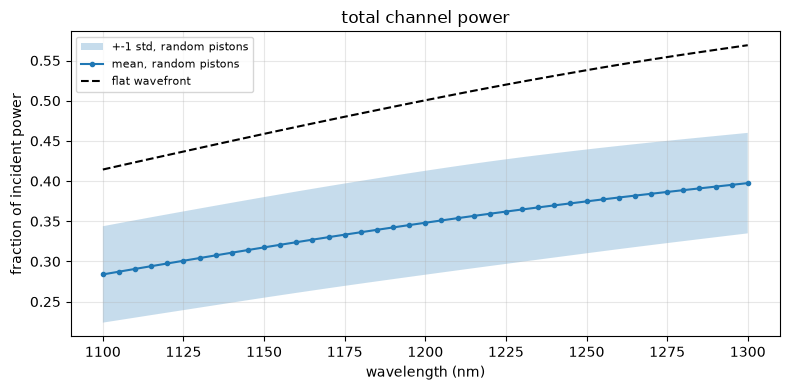

largest steps of the mean total power between neighbouring wavelengths:
  1105 -> 1110 nm: 0.287 -> 0.291
  1100 -> 1105 nm: 0.284 -> 0.287
  1110 -> 1115 nm: 0.291 -> 0.294


In [19]:
m_tot = plot_total_power(lam, SB_tr, ramp_file=S["ramp"])   # ramp: multi_wavelength.ipynb
print("largest steps of the mean total power between neighbouring wavelengths:")
for j in np.argsort(-np.abs(np.diff(m_tot)))[:3]:
    print(f"  {lam[j]:.0f} -> {lam[j + 1]:.0f} nm: {m_tot[j]:.3f} -> {m_tot[j + 1]:.3f}")

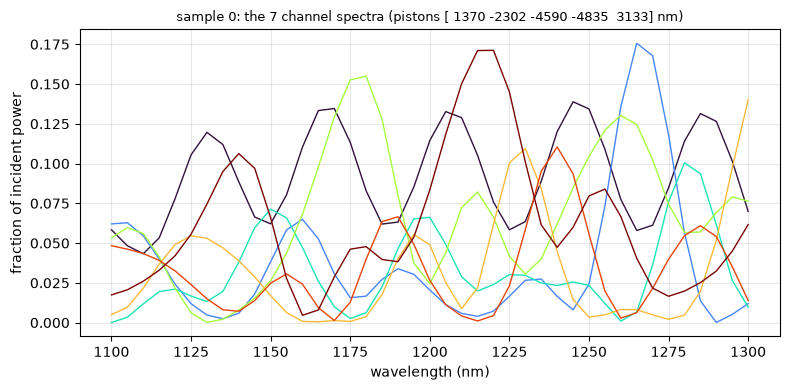

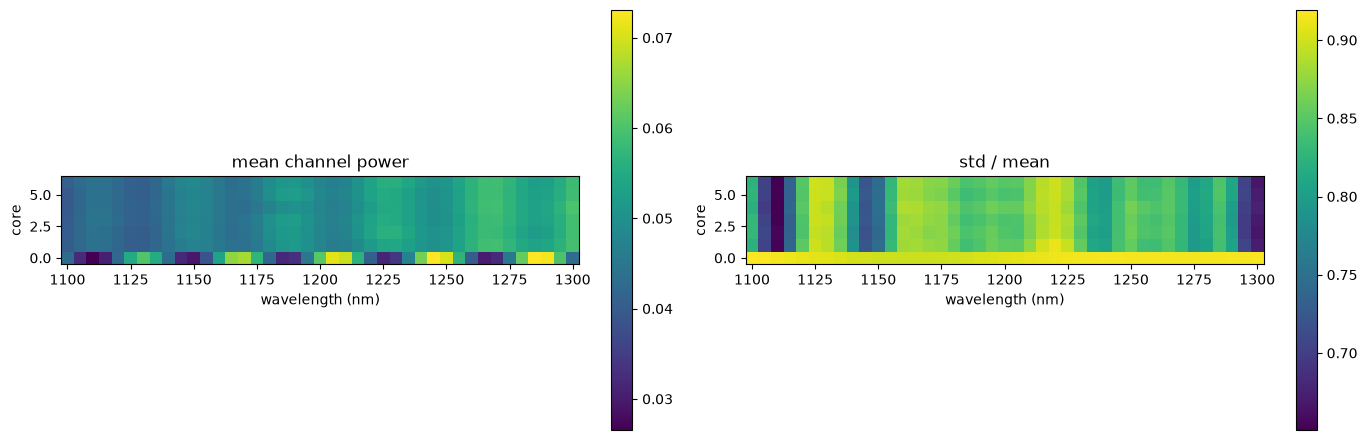

In [20]:
plot_sample_spectra(lam, SB_tr, CB_tr, i=0)
plot_spectral_maps(lam, SB_tr)

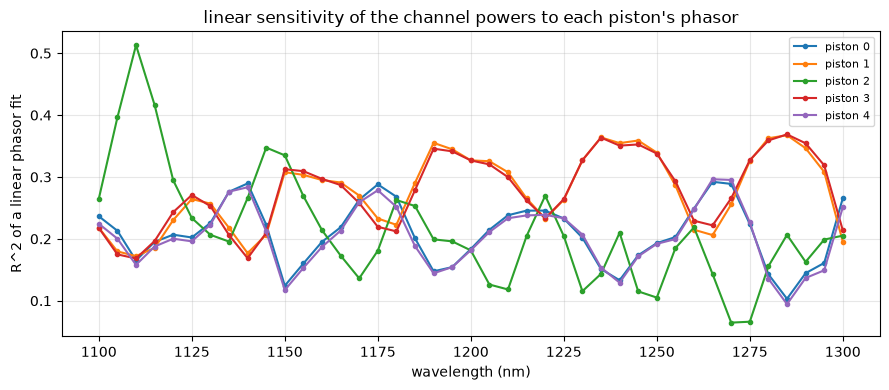

In [21]:
rows_s = ml.subsample_rows(len(SB_tr), 0.25, seed=2)
R2 = phasor_r2(X3B_tr[rows_s], CB_tr[rows_s], lam)
plot_per_piston(lam, R2, "wavelength (nm)", "R^2 of a linear phasor fit",
                "linear sensitivity of the channel powers to each piston's phasor")

## B2. Single models on the whole spectrum

### k-nearest neighbours

In [22]:
from sklearn.neighbors import KNeighborsRegressor

knnB = cacheB("kNN", lambda: KNeighborsRegressor(5, weights="distance").fit(XB_tr, YB_tr))
score(RESULTS_B, "kNN", knnB.predict(XB_va), CB_va, ys=ysB)
DOF_B["kNN"] = n_dof(knnB)

[cache] loaded kNN


kNN                    mean  1601.39 nm   per piston [1630.75 1578.56 1553.87 1589.62 1654.15]


### Dense degree-2 polynomial ridge on a wavelength subset

Every degree-2 monomial of the core signals at every `WL_STRIDE`-th
wavelength (raw signals, or their per-wavelength Zernike projection with
`REPR = "zern"`), one ridge per piston. The number of terms grows
quadratically with the inputs and the memory linearly with the rows, so the
fit uses a random `DATA_SHARE` of the training and validation rows, and
checks the memory needed first. It is scored on that validation subset only.

In [23]:
REPR, WL_STRIDE, DEGREE_R = "fiber", 4, 2
DATA_SHARE_R, MEM_BUDGET_GIB = 0.15, 128.0
wl_fit = np.arange(0, n_wl, WL_STRIDE)

proj_R = ml.modal_projector(ml.zernike_basis(dsB.core_xy, S["zern_spectral"], fill=0.8)[0]) if REPR == "zern" else None
to_features = lambda S: spectral_features(S, wl_fit, proj_R)
fsB = ml.Standardizer(eps=1e-9).fit(to_features(SB_tr))
fit_rows = ml.subsample_rows(len(SB_tr), DATA_SHARE_R, seed=0)
val_rows = ml.subsample_rows(len(SB_va), DATA_SHARE_R, seed=1)
F_fit, F_val = fsB.transform(to_features(SB_tr[fit_rows])), fsB.transform(to_features(SB_va[val_rows]))

In [24]:
n_terms_R = ml.n_poly_terms(F_fit.shape[1], DEGREE_R)
need_gib = (1.5 * len(F_fit) + len(F_val)) * n_terms_R * 8 / 2**30   # RidgeCV needs ~0.5x Z_fit extra
print(f"{len(wl_fit)} wavelengths x {F_fit.shape[1] // len(wl_fit)} {REPR} = {F_fit.shape[1]} inputs "
      f"-> {n_terms_R:,} terms; {len(F_fit)} fit / {len(F_val)} val rows -> ~{need_gib:.1f} GiB")
assert need_gib <= MEM_BUDGET_GIB, "lower DATA_SHARE_R (linear) or raise WL_STRIDE (quadratic)"

ridgeB = cacheB(f"{REPR}-ridge-d{DEGREE_R}-w{len(wl_fit)}-n{len(F_fit)}",
                lambda: ml.fit_dense_poly_ridge(F_fit, YB_tr[fit_rows], DEGREE_R, alphas=np.logspace(-2, 6, 17)))
DOF_B[f"{REPR}-ridge-d{DEGREE_R}"] = n_dof(ridgeB)
score(RESULTS_B, f"{REPR}-ridge-d{DEGREE_R}", ysB.inverse(ml.predict_dense_poly_ridge(ridgeB, F_val)),
      CB_va[val_rows], note=f"   (on {len(val_rows)} validation rows)");

11 wavelengths x 7 fiber = 77 inputs -> 3,080 terms; 6000 fit / 1500 val rows -> ~0.2 GiB
[cache] loaded fiber-ridge-d2-w11-n6000
fiber-ridge-d2         mean  1488.23 nm   per piston [1536.71 1503.96 1388.83 1457.69 1553.98]   (on 1500 validation rows)


### One global polynomial model (OMP)

A single degree-3 OMP model per piston on the core signals of several
wavelengths at once, regressing the piston directly. The number of terms
grows as (inputs)^3, so only a subset of wavelengths and cores fits in
memory. It is fitted on the same 20% of the training rows as the
per-wavelength models of B3.

In [25]:
DATA_SHARE_W = 0.2
rows_W = ml.subsample_rows(len(X3B_tr), DATA_SHARE_W, seed=0)   # shared with B3

WL_G, FIB_G, K_G, SCREEN_G = np.arange(0, n_wl, S["wl_stride_global"]), np.arange(n_cores), 1000, 6000
F_tr = X3B_tr[rows_W][:, WL_G][:, :, FIB_G].reshape(len(rows_W), -1)
F_va = X3B_va[:, WL_G][:, :, FIB_G].reshape(len(X3B_va), -1)
print(f"{len(WL_G)} wavelengths x {len(FIB_G)} cores = {F_tr.shape[1]} inputs -> "
      f"{ml.n_poly_terms(F_tr.shape[1], 3):,} degree-3 terms, {len(rows_W)} training rows")
globB = cacheW(f"global-d3-K{K_G}-w{len(WL_G)}-f{len(FIB_G)}-n{len(rows_W)}",
               lambda: ml.fit_omp_poly(F_tr, CB_tr[rows_W], 3, K_G, SCREEN_G))
score(RESULTS_B, "global OMP", ml.predict_omp_poly(globB, F_va), CB_va)
DOF_B["global OMP"] = n_dof(globB)

6 wavelengths x 7 cores = 42 inputs -> 14,189 degree-3 terms, 8000 training rows
[cache] loaded global-d3-K1000-w6-f7-n8000


global OMP             mean  2248.89 nm   per piston [2245.62 2269.89 2139.09 2322.1  2267.74]


### MLP on the full spectrum

Four hidden layers of 256 units on all 41 x n_cores inputs, Adam, 10000 epochs
(about 5 minutes on a GPU). Its best epoch comes at or near the end of the
run on the lanterns studied so far, so it may not have finished converging.


MLP [287, 256, 256, 256, 256, 5]: best epoch 9892 of 10000


MLP (all wl)           mean   278.03 nm   per piston [308.93 257.9  262.78 264.4  296.14]


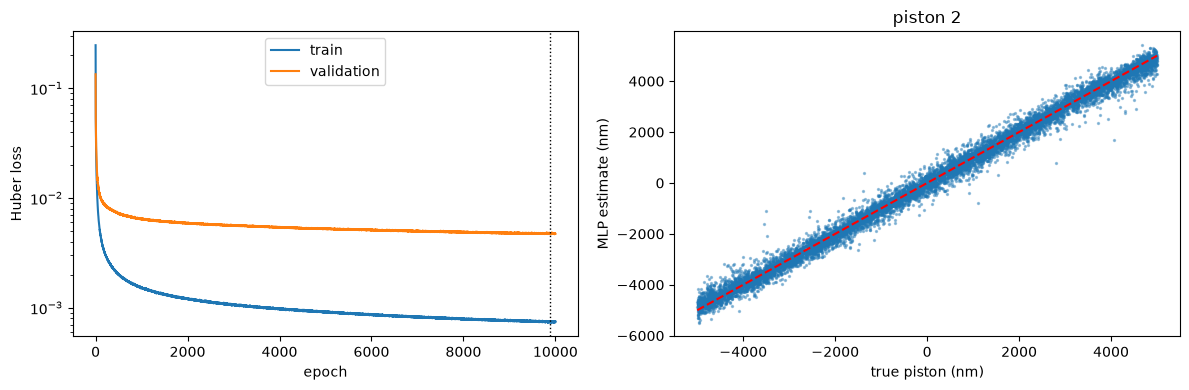

In [26]:
LAYERS_B = [XB_tr.shape[1], 256, 256, 256, 256, M_MODES]
EPOCHS_B, LR_B = 10000, 3e-4
MLP_B = f"{DATA}/cache_spectral/mlp-{'x'.join(map(str, LAYERS_B))}-e{EPOCHS_B}-lr{LR_B:g}.npz"
paramsB, histB = fit_or_load_mlp(MLP_B, LAYERS_B, XB_tr, YB_tr, XB_va, YB_va, epochs=EPOCHS_B, lr=LR_B,
                                 retrain=RETRAIN)
CB_mlp = ysB.inverse(np.asarray(ml.mlp_forward(paramsB, XB_va)))
score(RESULTS_B, "MLP (all wl)", CB_mlp, CB_va)
DOF_B["MLP (all wl)"] = n_dof(paramsB)
plot_mlp(histB, CB_va, CB_mlp, k=2, span=B_SPAN_NM, s=2)

## B3. Per-wavelength models of the wrapped piston

At wavelength lambda the signals depend on a piston only modulo lambda (the
pupil phase is 2 pi p / lambda). So one degree-3 OMP polynomial (at most K
terms) of the core signals per wavelength in `WL_USE` regresses the phasor
(sin, cos)(2 pi p / T) of each piston wrapped at the period T = lambda, on
the training rows `rows_W`.

In [27]:
WRAP_FACTOR = 1.0                  # period = WRAP_FACTOR * lambda (0.5 also works, same accuracy:
                                   # a function of p mod lambda/2 is one of p mod lambda)
WL_USE = np.arange(0, n_wl, 2)     # 21 of the 41 wavelengths
FIB_USE = np.arange(n_cores)       # all cores
DEGREE_W, K_W, SCREEN_W = 3, S["k_wrap"], 2000    # 19 cores: 1000 of 1539 terms; 7 cores: all 119

periods = lam * WRAP_FACTOR
TAG_W = f"wrap{WRAP_FACTOR:g}-d{DEGREE_W}-K{K_W}-f{len(FIB_USE)}-n{len(rows_W)}"
fitW = ml.fit_wrapped_models(
    X3B_tr, X3B_va, CB_tr, CB_va, periods, WL_USE, FIB_USE, degree=DEGREE_W, K=K_W, screen=SCREEN_W,
    cache=cacheW, rows=rows_W, tag=TAG_W)
print(f"{len(WL_USE)} per-wavelength models ({fitW['seconds']:.0f} s)")

[cache] loaded wrap1-d3-K119-f7-n8000-w0
[cache] loaded wrap1-d3-K119-f7-n8000-w2
[cache] loaded wrap1-d3-K119-f7-n8000-w4


[cache] loaded wrap1-d3-K119-f7-n8000-w6
[cache] loaded wrap1-d3-K119-f7-n8000-w8


[cache] loaded wrap1-d3-K119-f7-n8000-w10
[cache] loaded wrap1-d3-K119-f7-n8000-w12
[cache] loaded wrap1-d3-K119-f7-n8000-w14


[cache] loaded wrap1-d3-K119-f7-n8000-w16
[cache] loaded wrap1-d3-K119-f7-n8000-w18
[cache] loaded wrap1-d3-K119-f7-n8000-w20


[cache] loaded wrap1-d3-K119-f7-n8000-w22
[cache] loaded wrap1-d3-K119-f7-n8000-w24
[cache] loaded wrap1-d3-K119-f7-n8000-w26


[cache] loaded wrap1-d3-K119-f7-n8000-w28
[cache] loaded wrap1-d3-K119-f7-n8000-w30
[cache] loaded wrap1-d3-K119-f7-n8000-w32


[cache] loaded wrap1-d3-K119-f7-n8000-w34
[cache] loaded wrap1-d3-K119-f7-n8000-w36
[cache] loaded wrap1-d3-K119-f7-n8000-w38


[cache] loaded wrap1-d3-K119-f7-n8000-w40
21 per-wavelength models (2 s)


wrapped-piston RMSE per wavelength [nm]  (chance ~ period / sqrt(12))
   lambda | +-T/2 |    p0    p1    p2    p3    p4
   1100.0 |   550 | 193.9 190.4 161.6 191.4 196.7
   1110.0 |   555 | 193.3 193.8 119.4 196.7 197.6
   1120.0 |   560 | 193.4 189.6 168.2 190.1 196.7
   1130.0 |   565 | 199.7 193.7 184.8 193.7 200.9
   1140.0 |   570 | 187.2 193.1 173.6 190.2 189.2
   1150.0 |   575 | 185.1 182.7 171.2 181.7 187.3
   1160.0 |   580 | 207.8 188.5 190.8 190.1 207.2
   1170.0 |   585 | 195.5 199.4 202.0 198.2 200.9
   1180.0 |   590 | 201.1 211.0 175.5 209.4 203.9
   1190.0 |   595 | 205.8 177.3 194.4 181.8 209.3
   1200.0 |   600 | 215.6 187.9 209.0 191.8 216.3
   1210.0 |   605 | 211.6 203.5 209.3 200.9 212.7
   1220.0 |   610 | 223.0 230.0 163.5 227.6 228.5
   1230.0 |   615 | 214.1 198.0 205.1 196.5 217.9
   1240.0 |   620 | 223.6 188.0 209.3 186.7 224.7
   1250.0 |   625 | 223.4 203.3 204.3 200.6 224.8
   1260.0 |   630 | 214.1 227.0 179.5 225.8 218.6
   1270.0 |   635 | 213.0 219.

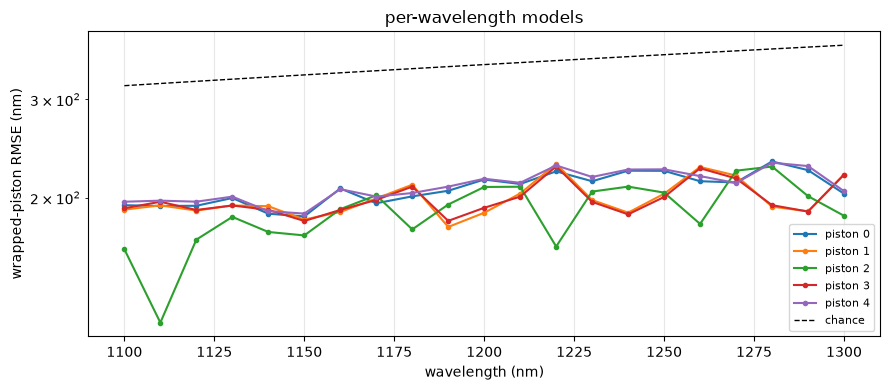

In [28]:
print_wrapped_table(fitW, lam)
plot_per_piston(lam[WL_USE], fitW["sig_va"], "wavelength (nm)", "wrapped-piston RMSE (nm)",
                "per-wavelength models", logy=True, ref=fitW["periods"] / np.sqrt(12), ref_label="chance")

## B4. Multi-wavelength unwrap

The wrapped estimates of all wavelengths in `WL_USE` are fused into the
full-range piston (`ml_reconstruct.unwrap`: a circular maximum-likelihood
search over the whole +-5 um range, then a robust refinement), as in
synthetic-wavelength interferometry. A "wrong fringe" is an error larger than
half the shortest period.

per-wl OMP + unwrap    mean  1664.92 nm   per piston [1928.18 1593.71 1219.1  1615.95 1967.66]

 piston | RMSE (nm) | bias (nm) | wrong fringe | best single wl, no unwrap
   0    |   1928.18 |    +42.26 |      58.00% |      2891
   1    |   1593.71 |    +14.25 |      52.30% |      2888
   2    |   1219.10 |     -4.55 |      43.73% |      2875
   3    |   1615.95 |     +8.42 |      52.72% |      2917
   4    |   1967.66 |    -15.20 |      57.10% |      2906
  mean  |   1664.92 |           |      52.77% |


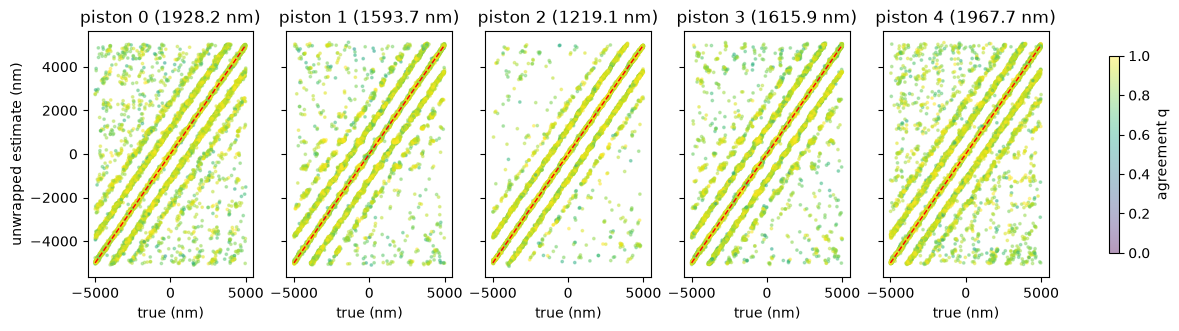

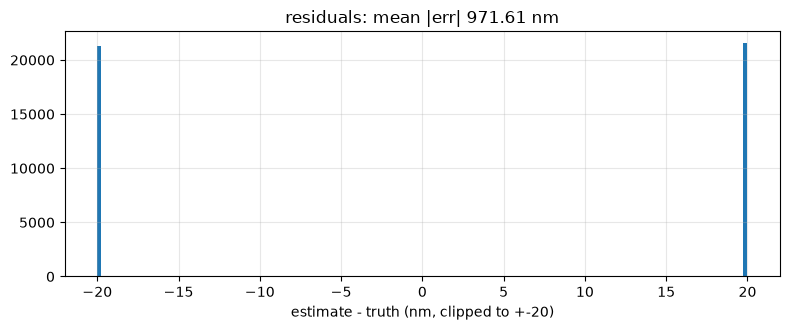

In [29]:
P_hat, Q = ml.unwrap_all(fitW, B_SPAN_NM)
score(RESULTS_B, "per-wl OMP + unwrap", P_hat, CB_va)
cacheW.verbose = False                 # summed over the per-wavelength models
DOF_B["per-wl OMP + unwrap"] = sum(n_dof(cacheW(f"{TAG_W}-w{w}", None)) for w in WL_USE)
cacheW.verbose = True
print()
print_unwrap_table(P_hat, CB_va, fitW)
plot_unwrap(P_hat, CB_va, Q, B_SPAN_NM)

## B5. Part B comparison

  no skill (mean)         2893.08 nm   per piston [2888.28 2880.81 2891.36 2908.63 2896.31]           1 dof/piston
  kNN                     1601.39 nm   per piston [1630.75 1578.56 1553.87 1589.62 1654.15]   11,520,000 dof/piston
  fiber-ridge-d2          1488.23 nm   per piston [1536.71 1503.96 1388.83 1457.69 1553.98]       3,081 dof/piston
  global OMP              2248.89 nm   per piston [2245.62 2269.89 2139.09 2322.1  2267.74]       1,001 dof/piston
  MLP (all wl)             278.03 nm   per piston [308.93 257.9  262.78 264.4  296.14]      54,478 dof/piston
  per-wl OMP + unwrap     1664.92 nm   per piston [1928.18 1593.71 1219.1  1615.95 1967.66]       2,499 dof/piston


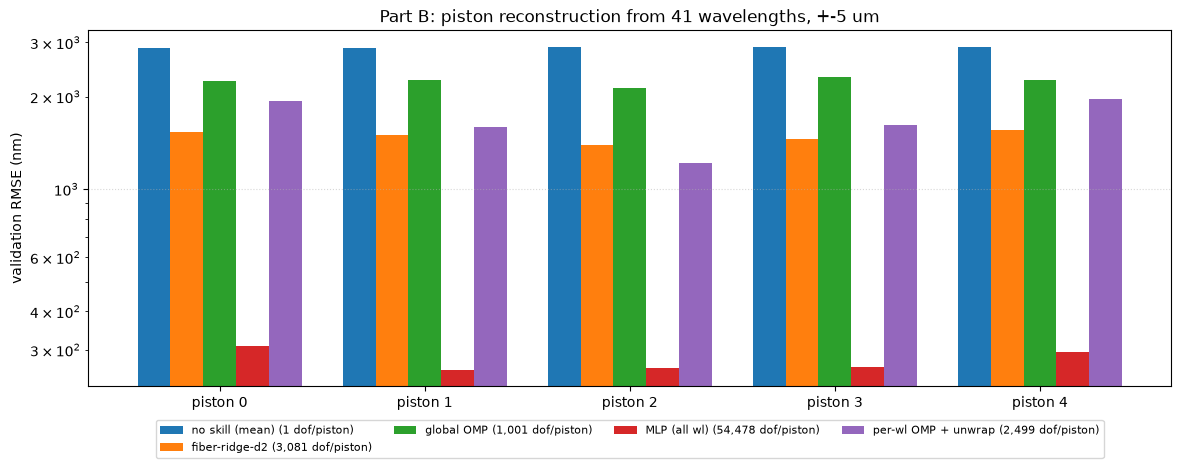

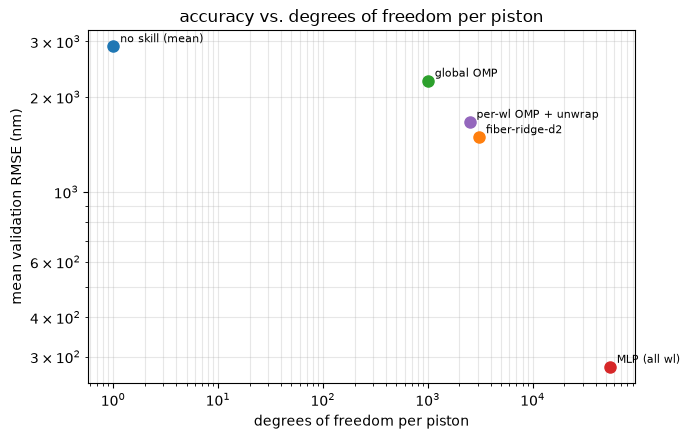

In [30]:
show_results(RESULTS_B, "Part B: piston reconstruction from 41 wavelengths, +-5 um",
             dof=DOF_B, exclude=("kNN",))

## B6. Part B: what differs between lanterns

- *pl19_800:* the per-wavelength OMP models + unwrap give the best result
  (1.64 nm); the full-spectrum MLP reaches 10.25 nm.
- *pl7_1200:* the per-wavelength route fails (1688 nm, 52% wrong fringes):
  each per-wavelength model has to recover pistons wrapped over a full
  +-lambda/2, the single-wavelength regime where 7 signals are ambiguous
  (Part A), so its wrapped error (~200 nm, against ~350 nm for chance) is far
  too large for the unwrap. Only the full-spectrum MLP learns much (258 nm
  against 2893 nm for no skill): it sees all wavelengths at once, enough
  signals to resolve what no single wavelength can.
- *pl19_1200:* see its executed copy in `runs/pl19_1200/`.


# Summary

Every model of Parts A and B. The parts are not directly comparable:
different ranges (+-span vs +-5 um), signals (camera at the design wavelength
with unit coupled power vs. channel power fractions at 41 wavelengths) and
training-set sizes.


In [31]:
print(f"{'':36s} {'mean RMSE':>10s}   per piston [nm]")
for part, res in [(f"A  {LANTERN}, one wavelength, +-{A_SPAN_NM:.0f} nm", RESULTS_A),
                  (f"B  {LANTERN}, 41 wl, +-5 um", RESULTS_B)]:
    print(part)
    for m, r in sorted(res.items(), key=lambda kv: kv[1].mean()):
        print(f"  {m:34s} {r.mean():10.2f}   {np.round(r, 2)}")


                                      mean RMSE   per piston [nm]
A  pl7_1200, one wavelength, +-500 nm
  MLP                                    226.44   [229.92 230.88 206.04 239.12 226.22]
  fiber-omp-K119                         228.50   [230.6  233.06 217.84 235.   225.97]
  fiber-omp-K40                          237.72   [242.18 239.85 226.43 243.93 236.22]
  kNN                                    239.33   [235.27 247.38 225.51 252.29 236.18]
  fiber-d2                               243.20   [246.47 247.68 232.76 246.76 242.35]
B  pl7_1200, 41 wl, +-5 um
  MLP (all wl)                           278.03   [308.93 257.9  262.78 264.4  296.14]
  fiber-ridge-d2                        1488.23   [1536.71 1503.96 1388.83 1457.69 1553.98]
  kNN                                   1601.39   [1630.75 1578.56 1553.87 1589.62 1654.15]
  per-wl OMP + unwrap                   1664.92   [1928.18 1593.71 1219.1  1615.95 1967.66]
  global OMP                            2248.89   [2245.62 2269.89 2139